# Partie I — Apprentissage supervisé (Q1 → Q9) : Train/Test Split + Mise en production

## Objectif
Dans cette partie, on construit un **processus complet de classification supervisée** sur le jeu de données *credit_scoring.csv* :
1) Charger le dataset et analyser la répartition de la cible  
2) Comparer plusieurs classifieurs sur les **données brutes**  
3) Refaire la comparaison après **normalisation** (StandardScaler)  
4) Ajouter une **ACP** (3 composantes) puis concaténer aux variables normalisées (stratégie hybride) et comparer à nouveau  
5) Étudier l’**importance des variables**, sélectionner un nombre optimal de variables  
6) Effectuer une **recherche de paramètres** (GridSearchCV) sur le modèle retenu  
7) Construire un **pipeline final “production”** (prétraitement + sélection + modèle) et le sauvegarder en `.pkl`  
8) Vérifier que le pipeline est exploitable (prédiction / probas)  
9) Préparer la partie “mise en production / API” : tests simples du modèle sauvegardé

## Protocole expérimental
- **Split** : 50% train / 50% test, avec **stratification** (même proportion de classes dans train et test).
- **Modèles comparés** (baseline) :
  - CART (arbre de décision)
  - KNN
  - MLP (réseau de neurones)
- **Évaluations affichées** :
  - Matrice de confusion
  - Accuracy, Précision, Rappel
  - AUC (ROC)
  - Courbes ROC superposées
- **Score métier retenu** :
  \[
  \text{Score final} = \frac{\text{Accuracy} + \text{Précision}}{2}
  \]
  (objectif : un compromis performance globale + limitation des faux positifs)

## Exécution
La cellule suivante lance toute l’orchestration **Q1 → Q9** : comparaison brute, normalisée, normalisée+ACP, sélection, tuning, puis création/sauvegarde du pipeline final.



================= PARTIE 1 : Q1 → Q9 (TRAIN/TEST SPLIT) =================

=========== ÉTAPE 0 : Chargement & Split ===========
Dataset : (4375, 14)
Répartition : 3159 Positifs (72.21%) / 1216 Négatifs

=========== ÉTAPE 1 : Données BRUTES ===========

--- CART ---
Matrice :
[[ 297  311]
 [ 319 1261]]
Accuracy : 0.712 | Précision : 0.802 | Rappel : 0.798
AUC      : 0.643
👉 Score Final : 0.757

--- KNN ---
Matrice :
[[ 180  428]
 [ 221 1359]]
Accuracy : 0.703 | Précision : 0.760 | Rappel : 0.860
AUC      : 0.648
👉 Score Final : 0.732

--- MLP ---
Matrice :
[[  59  549]
 [  55 1525]]
Accuracy : 0.724 | Précision : 0.735 | Rappel : 0.965
AUC      : 0.679
👉 Score Final : 0.730


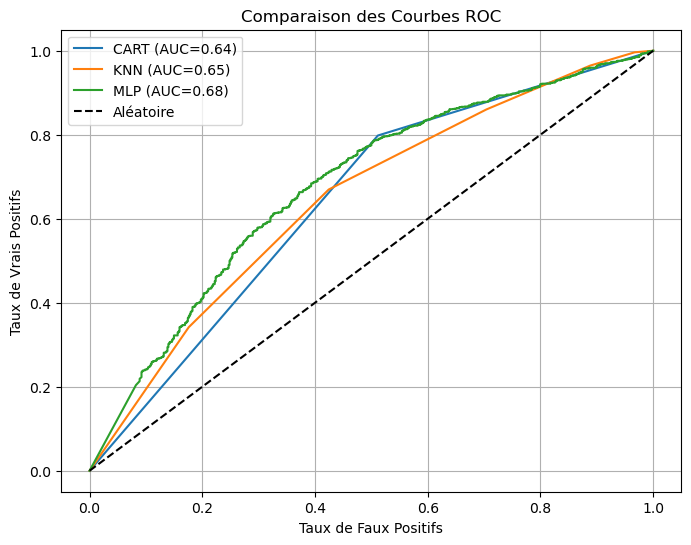


🏆 Le meilleur modèle est : CART avec un score de 0.757

=========== ÉTAPE 2 : Données NORMALISÉES ===========

COMPARAISON APRÈS NORMALISATION

--- CART ---
Matrice :
[[ 302  306]
 [ 322 1258]]
Accuracy : 0.713 | Précision : 0.804 | Rappel : 0.796
AUC      : 0.646
👉 Score Final : 0.759

--- KNN ---
Matrice :
[[ 270  338]
 [ 212 1368]]
Accuracy : 0.749 | Précision : 0.802 | Rappel : 0.866
AUC      : 0.744
👉 Score Final : 0.775

--- MLP ---
Matrice :
[[ 353  255]
 [ 221 1359]]
Accuracy : 0.782 | Précision : 0.842 | Rappel : 0.860
AUC      : 0.817
👉 Score Final : 0.812


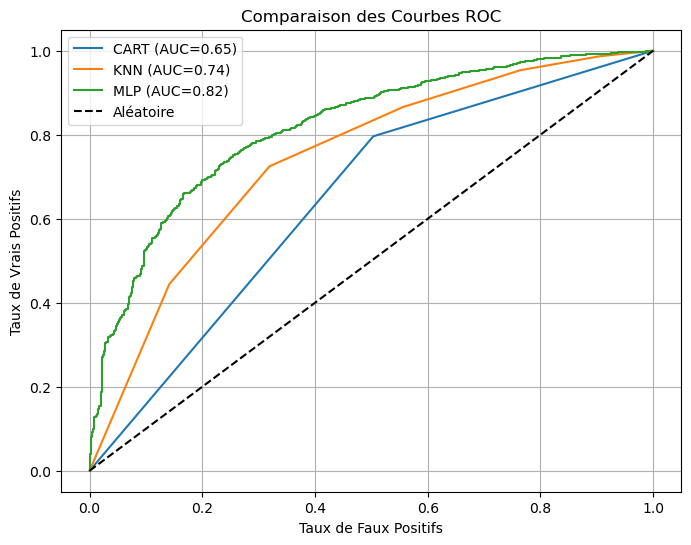


🏆 Le meilleur modèle est : MLP avec un score de 0.812

=========== ÉTAPE 3 : NORMALISÉ + ACP (Hybride) ===========
--- Calcul ACP et Concaténation ---
✅ Dimensions après concaténation : (2187, 16) (16 variables)

COMPARAISON SUR DONNÉES NORMALISÉES + ACP (Stratégie Hybride)

--- CART ---
Matrice :
[[ 305  303]
 [ 296 1284]]
Accuracy : 0.726 | Précision : 0.809 | Rappel : 0.813
AUC      : 0.657
👉 Score Final : 0.768

--- KNN ---
Matrice :
[[ 258  350]
 [ 206 1374]]
Accuracy : 0.746 | Précision : 0.797 | Rappel : 0.870
AUC      : 0.743
👉 Score Final : 0.771

--- MLP ---
Matrice :
[[ 353  255]
 [ 210 1370]]
Accuracy : 0.787 | Précision : 0.843 | Rappel : 0.867
AUC      : 0.821
👉 Score Final : 0.815


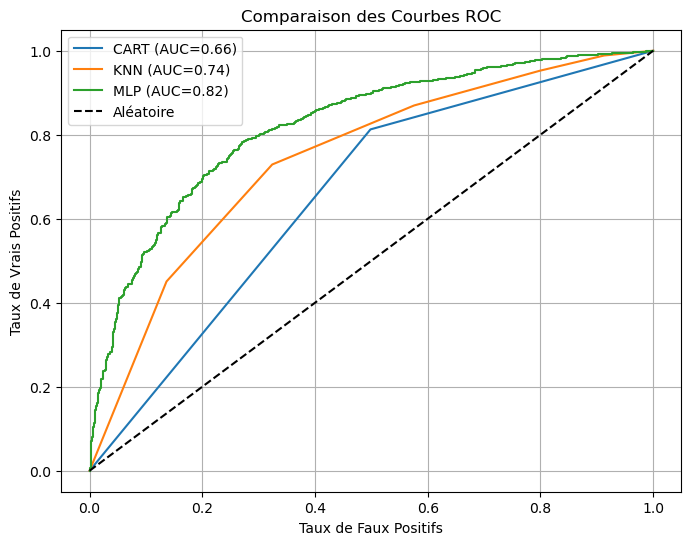


🏆 Le meilleur modèle est : MLP avec un score de 0.815

=========== ÉTAPE 4 : IMPORTANCE & SÉLECTION ===========

--- 1. Importance (RF) ---
Top 5 variables : ['Income' 'PCA2' 'Seniority' 'PCA3' 'Price']


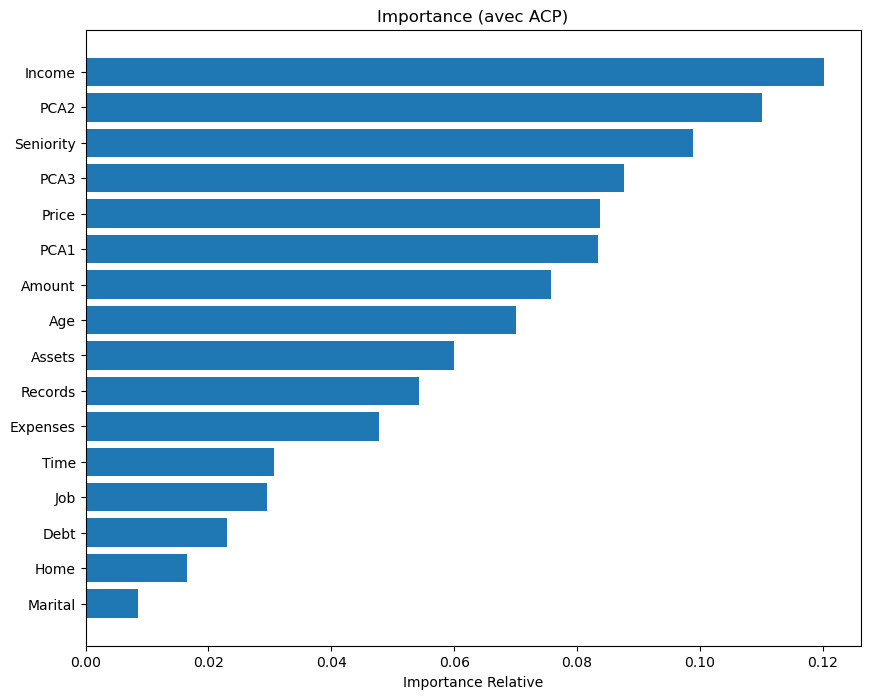


--- 2. Sélection Optimale (MLP) ---


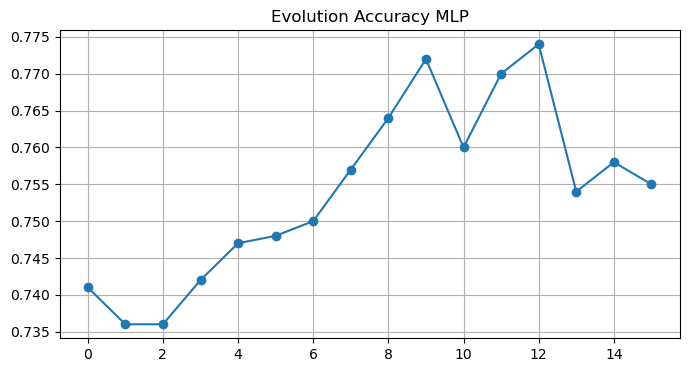

👉 Nombre optimal trouvé : 13

--- 3. Explicabilité (SHAP) ---


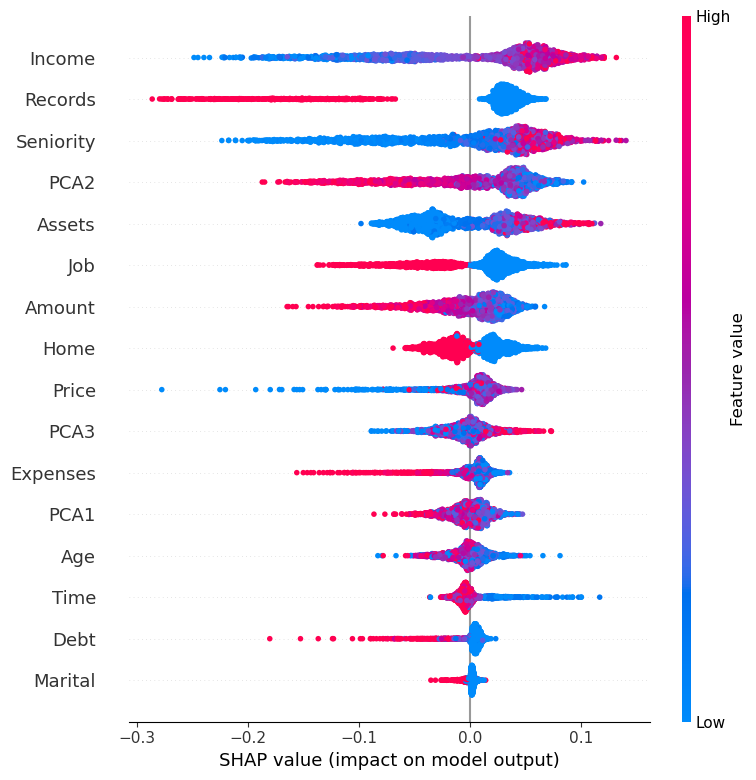


=========== ÉTAPE 5 : TUNING DU MLP ===========

--- Optimisation du MLP sur les 13 meilleures variables ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits
✅ Meilleurs paramètres trouvés : {'alpha': 0.0001, 'hidden_layer_sizes': (40, 20), 'learning_rate_init': 0.001, 'solver': 'adam'}
✅ Meilleur score de validation (CV) : 0.785

=========== ÉTAPE 6 : PIPELINE FINAL ===========

--- Création du Pipeline de Production  ---
Nombre de variables sélectionnées (best_k) : 13
✅ Pipeline sauvegardé sous 'credit_scoring.pkl'

=========== ORCHESTRATION TERMINÉE ✅ ===========

✅ Pipeline final (train/test) :


,steps,"[('S', ...), ('FU', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,transformer_list,"[('ID', ...), ('PCA', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False


In [2]:
# ============================================================
# CELLULE UNIQUE - RENDU COMPLET (Q1 → Q9 puis Q10)
# ============================================================

from sklearn import set_config
set_config(display="diagram")

# Recharge utils si tu l'as modifié récemment

from utils import pipeline_generation_train_test_split, pipeline_generation_cv

print("\n================= PARTIE 1 : Q1 → Q9 (TRAIN/TEST SPLIT) =================")
pipeline_final = pipeline_generation_train_test_split("credit_scoring.csv")

print("\n✅ Pipeline final (train/test) :")
pipeline_final


## Analyse et interprétation des résultats (Q1 → Q9)

### Q1–Q2 — Comparaison des classifieurs sur données brutes
Sur les **données brutes**, les performances restent globalement limitées en **AUC** (ROC proches de la diagonale), ce qui traduit une séparation des classes **modérée** sans prétraitement.  
Les scores obtenus montrent que :
- **CART** est le meilleur selon le **score final (acc + précision)/2**, mais avec une AUC faible (~0.64).
- **KNN** et **MLP** ne dépassent pas CART sur ce jeu *non normalisé*, ce qui est cohérent car ces modèles sont sensibles aux échelles des variables.

➡️ Conclusion : **les données brutes ne sont pas dans un format optimal** pour KNN/MLP.

---

### Q3 — Effet de la normalisation (StandardScaler)
Après **StandardScaler**, on observe une amélioration nette des modèles sensibles à l’échelle :
- **MLP** devient le meilleur modèle avec une hausse importante de **l’AUC** (~0.82).
- **KNN** progresse également (meilleure ROC), ce qui confirme l’intérêt du centrage-réduction.
- **CART** varie peu, ce qui est normal : un arbre est peu sensible au scaling.

➡️ Conclusion : **la normalisation est indispensable** pour obtenir de bonnes performances avec KNN/MLP.

---

### Q4 — Ajout de variables issues d’une ACP (stratégie hybride : normalisé + PCA)
On concatène ensuite les **variables normalisées** avec **3 composantes PCA**, ce qui donne **16 variables** au total.  
Les résultats montrent :
- **MLP** reste le meilleur et gagne légèrement (AUC ~0.821).
- Les courbes ROC confirment un gain cohérent : l’ACP capture une partie de l’information sous forme de combinaisons linéaires utiles.

➡️ Conclusion : l’ACP apporte un **gain léger mais stable** (et améliore la représentation).

---

### Q5 — Sélection de variables (importance RF + choix de k)
L’analyse d’importance par RandomForest met en évidence des variables dominantes :
- **Income**, **PCA2**, **Seniority**, **PCA3**, **Price** sont les plus influentes.

Ensuite, le test de performance en faisant varier le nombre de variables montre un optimum à :
- **best_k = 13**

➡️ Conclusion : on retient **13 variables**, car c’est le meilleur compromis performance / complexité.

---

### Q5 (suite) — Explicabilité SHAP
Le résumé SHAP confirme l’importance des variables déjà repérées :
- les plus fortes contributions globales proviennent notamment de **Income**, **Records**, **Seniority**, ainsi que certaines composantes **PCA**.

➡️ Conclusion : l’explicabilité valide la sélection : **les variables retenues ont un impact réel** sur la décision.

---

### Q6 — Recherche des meilleurs paramètres (tuning MLP)
Le **GridSearchCV** sur le MLP (avec le score métier) fournit :
- `hidden_layer_sizes=(40,20)`, `alpha=0.0001`, `learning_rate_init=0.001`, `solver='adam'`
- score moyen CV ~ **0.785**

➡️ Conclusion : le MLP optimisé est stable et cohérent, avec une architecture adaptée et une régularisation faible.

---

### Q7–Q9 — Création et sauvegarde du pipeline final “mise en production”
Le pipeline final sauvegardé (`credit_scoring.pkl`) enchaîne automatiquement :
1. **StandardScaler**
2. **FeatureUnion** : variables originales + **PCA(3)**
3. **RFE(RandomForest)** pour sélectionner **best_k = 13**
4. **MLP optimisé**

➡️ Conclusion : on obtient un **pipeline complet, reproductible et prêt production**, garantissant que les mêmes transformations sont appliquées en entraînement et en prédiction.


## Q10 — Validation croisée (étapes réalisées)

Objectif : comparer plusieurs algorithmes de classification de manière robuste avec une **validation croisée K-Fold (k=10)**, puis sélectionner le meilleur selon un **critère métier**.

### 1) Préparation de 3 jeux de données
- **Jeu original** : X brut (13 variables)
- **Jeu normalisé** : StandardScaler appliqué (13 variables)
- **Jeu normalisé + ACP** : ajout de 3 composantes PCA aux variables normalisées (16 variables)

### 2) Comparaison multi-algorithmes en validation croisée (10 folds)
Pour chaque classifieur, on calcule :
- **Accuracy moyenne ± écart-type**
- **AUC moyenne ± écart-type**
- **Score métier moyen ± écart-type**
  - Score métier = (accuracy + precision) / 2
- **Temps d’exécution**

### 3) Sélection du meilleur algorithme
- On retient le **meilleur score métier moyen** (sur le jeu **normalisé + ACP**).

### 4) Tuning du meilleur modèle
- Recherche de paramètres avec **GridSearchCV (5 folds)** sur le meilleur algorithme.

### 5) Sauvegarde du modèle final
- Entraînement du pipeline final sur l’ensemble du dataset
- Sauvegarde dans `credit_scoring_cv.pkl`


In [4]:
print("\n================= PARTIE 2 : Q10 (VALIDATION CROISÉE) =================")

import importlib, utils
importlib.reload(utils)

pipeline_cv, best_name, best_score, res_acp = utils.pipeline_generation_cv("credit_scoring.csv")

print("\n✅ Meilleur algo (CV, norm+ACP) :", best_name)
print("✅ Meilleur score métier moyen :", round(best_score, 3))

from sklearn import set_config
set_config(display="diagram")
pipeline_cv




================= PARTIE 2 : Q10 (VALIDATION CROISÉE) =================

=========== CV ÉTAPE 0 : Préparation des jeux de données ===========
Jeu original   : (4375, 13)
Jeu normalisé  : (4375, 13)
Jeu norm+ACP   : (4375, 16)

=========== CV ÉTAPE 1 : Construction des classifieurs ===========

=========== CV ÉTAPE 2 : Comparaison sur DONNÉES ORIGINALES ===========

===== VALIDATION CROISÉE SUR CE JEU DE DONNÉES =====
X shape : (4375, 13), y shape : (4375,)

--- CART ---
Accuracy        : 0.727 ± 0.025
AUC             : 0.656 ± 0.032
Score métier    : 0.767 ± 0.022
Temps (s)       : 0.63

--- ID3 ---
Accuracy        : 0.723 ± 0.024
AUC             : 0.664 ± 0.029
Score métier    : 0.769 ± 0.026
Temps (s)       : 0.28

--- Stump ---
Accuracy        : 0.722 ± 0.018
AUC             : 0.618 ± 0.028
Score métier    : 0.731 ± 0.019
Temps (s)       : 0.16

--- MLP_20_10 ---
Accuracy        : 0.685 ± 0.107
AUC             : 0.726 ± 0.034
Score métier    : 0.753 ± 0.045
Temps (s)       : 6.85



,steps,"[('S', ...), ('FU', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,transformer_list,"[('ID', ...), ('PCA', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False


## Q10 — Analyse et interprétation des résultats

### Résultats sur données originales (brutes)
- Les modèles simples (CART, ID3, Stump, KNN) ont des AUC plus faibles (~0.62–0.66).
- Les méthodes d’ensemble dominent :
  - **AdaBoost** : score métier ≈ 0.810
  - **XGB_200** : score métier ≈ 0.810
  - **RF / Bagging** : légèrement derrière (~0.802–0.804)
👉 Conclusion : sur données brutes, les **ensembles/boosting** sont les plus performants.

### Résultats sur données normalisées
- La normalisation améliore surtout les algorithmes sensibles à l’échelle :
  - **MLP** progresse fortement (score métier ≈ 0.809 au lieu de 0.753)
  - **KNN** progresse aussi (≈ 0.789 au lieu de 0.741)
- Les arbres/forêts changent peu (normalisation peu utile pour eux).
👉 Conclusion : la normalisation est **très utile** pour MLP/KNN, neutre pour les arbres.

### Résultats sur données normalisées + ACP
- Les performances restent proches de la normalisation seule :
  - **XGB_200** : score métier ≈ 0.810 ± 0.016
  - **AdaBoost** : ≈ 0.809 ± 0.015
  - **RF_200** : ≈ 0.802 ± 0.017
👉 Conclusion : l’ACP n’apporte pas un gain massif ici, mais garde un dataset stable et enrichi.

### Meilleur algorithme choisi
- Le meilleur (selon score métier moyen sur norm+ACP) est :
  - **XGB_200** avec **0.810**
- Il est au coude-à-coude avec AdaBoost, mais garde un bon compromis performance/temps.

### Tuning
- Le tuning améliore légèrement / confirme la stabilité :
  - Score tuning (CV 5-fold) ≈ **0.812**
  - Meilleurs paramètres trouvés : max_depth=4, n_estimators=200, learning_rate=0.1, subsample=0.8, colsample_bytree=1.0

### Pipeline final
- Le pipeline final a été sauvegardé sous : `credit_scoring_cv.pkl`
- Il correspond au modèle le plus robuste selon la validation croisée.


## Partie II.1 — Variables continues (numériques) sans données manquantes

Objectif : travailler uniquement sur les **6 variables numériques** du fichier `credit.data`, en **supprimant** les individus contenant des valeurs manquantes, puis **comparer** plusieurs algorithmes de classification.

### Étapes réalisées (conformes à l’énoncé)

1) **Chargement des données**
- Lecture du fichier avec `pandas.read_csv`
- Conversion `DataFrame -> numpy array` via `.values`
- Séparation :
  - `X` = variables caractéristiques (15 colonnes)
  - `y` = target (dernière colonne : `+` / `-`)

2) **Sous-ensemble numérique**
- Sélection des 6 variables continues (numériques) : A2, A3, A8, A11, A14, A15  
- Remplacement des `?` par `NaN`
- Conversion du tableau en `float` (`astype(float)`)

3) **Suppression des individus incomplets**
- Suppression des lignes ayant au moins un `NaN`

4) **Analyse des propriétés du dataset**
- Affichage de la taille (`shape`)
- Affichage de la répartition des classes (+ / -) (histogramme)
- **Binarisation de la target** : `+ -> 1` et `- -> 0`

5) **Comparaison des algorithmes (train/test split 50/50 stratifié)**
- Exécution de `run_classifiers_train_test` sur les données numériques **brutes**
- Ajout de **l’AUC** et affichage de la **courbe ROC** pour chaque modèle

### Normalisation des variables continues
On refait la comparaison sur les mêmes données numériques mais après normalisation :
- **StandardScaler** (centrage-réduction)
- **MinMaxScaler** (mise à l’échelle [0,1])

Les cellules ci-dessous exécutent donc deux expériences distinctes :
- Comparaison sur données numériques **normalisées StandardScaler**
- Comparaison sur données numériques **normalisées MinMaxScaler**



II.1) VARIABLES CONTINUES (NUMÉRIQUES) - SANS DONNÉES MANQUANTES

• Chargement des données et préparation :
  - Import pandas.read_csv ✅
  - Conversion DataFrame -> numpy (values) ✅
  - Séparation X (features) / y (target) ✅
  - Taille dataset brut (shape) : (688, 16)

• Création sous-ensemble des variables numériques :
  - Remplacement '?' -> NaN ✅
  - Typage float (astype) ✅

• Suppression des individus contenant des NaN :
  - Shape après nettoyage : (666, 6) ✅

• Analyse des propriétés :
  - Nombre d'exemples positifs (+) : 299
  - Nombre d'exemples négatifs  (-) : 367
  - Binarisation target (+->1, -->0) ✅


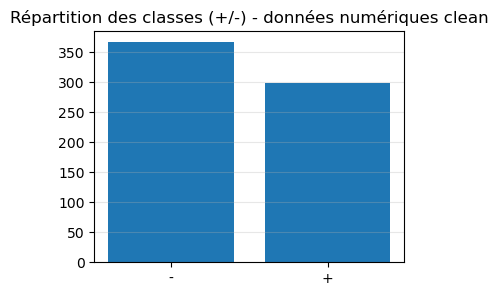


• Split train/test 50/50 (stratifié) :
  - Train : (333, 6) | Test : (333, 6)

• Comparaison des algorithmes (données numériques brutes) :
  - Critères affichés : Accuracy, Précision, Rappel, AUC + ROC ✅

--- CART ---
Matrice :
[[130  53]
 [ 43 107]]
Accuracy : 0.712 | Précision : 0.669 | Rappel : 0.713
AUC      : 0.712
👉 Score Final : 0.690

--- KNN ---
Matrice :
[[128  55]
 [ 64  86]]
Accuracy : 0.643 | Précision : 0.610 | Rappel : 0.573
AUC      : 0.683
👉 Score Final : 0.626

--- MLP ---
Matrice :
[[133  50]
 [ 63  87]]
Accuracy : 0.661 | Précision : 0.635 | Rappel : 0.580
AUC      : 0.663
👉 Score Final : 0.648


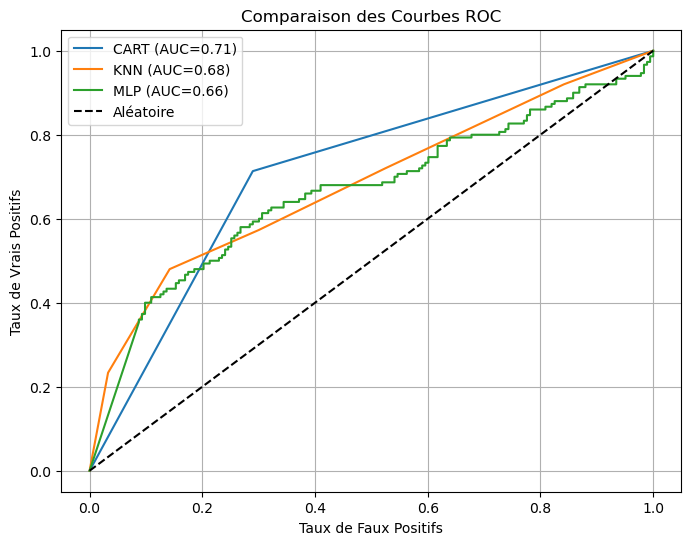


🏆 Le meilleur modèle est : CART avec un score de 0.690

• Normalisation des variables continues :
  - Normalisation utilisée : StandardScaler ✅

• Comparaison des algorithmes (données numériques normalisées) :

--- CART ---
Matrice :
[[130  53]
 [ 42 108]]
Accuracy : 0.715 | Précision : 0.671 | Rappel : 0.720
AUC      : 0.715
👉 Score Final : 0.693

--- KNN ---
Matrice :
[[163  20]
 [ 54  96]]
Accuracy : 0.778 | Précision : 0.828 | Rappel : 0.640
AUC      : 0.820
👉 Score Final : 0.803

--- MLP ---
Matrice :
[[146  37]
 [ 39 111]]
Accuracy : 0.772 | Précision : 0.750 | Rappel : 0.740
AUC      : 0.827
👉 Score Final : 0.761


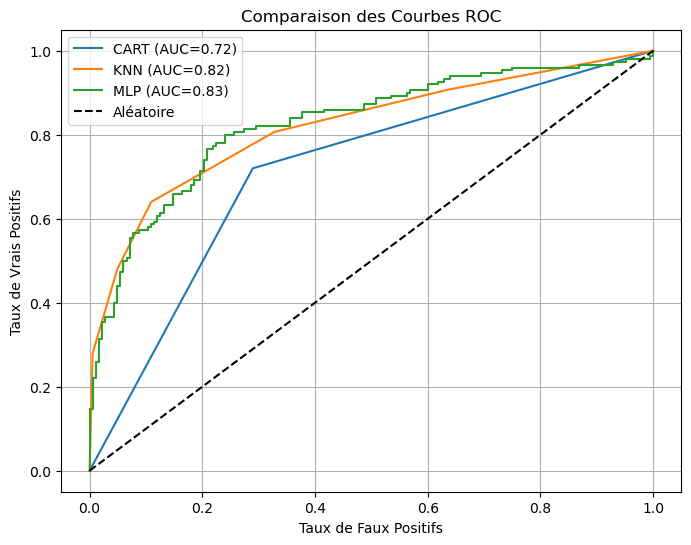


🏆 Le meilleur modèle est : KNN avec un score de 0.803

II.1) VARIABLES CONTINUES (NUMÉRIQUES) - SANS DONNÉES MANQUANTES

• Chargement des données et préparation :
  - Import pandas.read_csv ✅
  - Conversion DataFrame -> numpy (values) ✅
  - Séparation X (features) / y (target) ✅
  - Taille dataset brut (shape) : (688, 16)

• Création sous-ensemble des variables numériques :
  - Remplacement '?' -> NaN ✅
  - Typage float (astype) ✅

• Suppression des individus contenant des NaN :
  - Shape après nettoyage : (666, 6) ✅

• Analyse des propriétés :
  - Nombre d'exemples positifs (+) : 299
  - Nombre d'exemples négatifs  (-) : 367
  - Binarisation target (+->1, -->0) ✅


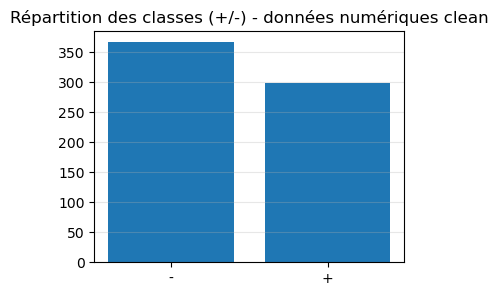


• Split train/test 50/50 (stratifié) :
  - Train : (333, 6) | Test : (333, 6)

• Normalisation des variables continues :
  - Normalisation utilisée : MinMaxScaler ✅

• Comparaison des algorithmes (données numériques normalisées) :

--- CART ---
Matrice :
[[130  53]
 [ 43 107]]
Accuracy : 0.712 | Précision : 0.669 | Rappel : 0.713
AUC      : 0.712
👉 Score Final : 0.690

--- KNN ---
Matrice :
[[150  33]
 [ 56  94]]
Accuracy : 0.733 | Précision : 0.740 | Rappel : 0.627
AUC      : 0.792
👉 Score Final : 0.736

--- MLP ---
Matrice :
[[149  34]
 [ 43 107]]
Accuracy : 0.769 | Précision : 0.759 | Rappel : 0.713
AUC      : 0.822
👉 Score Final : 0.764


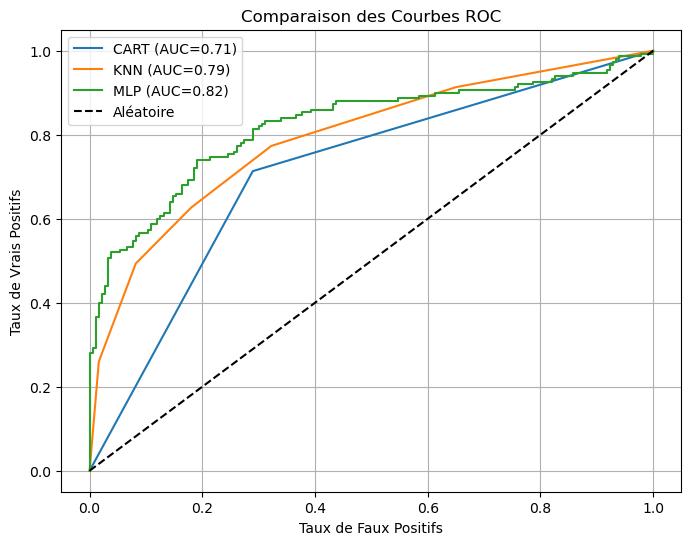


🏆 Le meilleur modèle est : MLP avec un score de 0.764


In [4]:
from utils_part2 import part2_run_numeric_no_missing

# 1) StandardScaler : on affiche brutes + normalisées
part2_run_numeric_no_missing("credit.data", scaler="standard", show_raw=True)

# 2) MinMaxScaler : on affiche seulement la partie normalisée (pas les brutes)
part2_run_numeric_no_missing("credit.data", scaler="minmax", show_raw=False)


## II.1 — Analyse / interprétation des résultats (réponse aux questions de l’énoncé)

### A) Propriétés du sous-ensemble numérique (après suppression des manquants)
Après nettoyage, on obtient :
- **Shape : (666, 6)** (666 individus, 6 variables numériques)
- **Positifs : 299** / **Négatifs : 367**
➡️ Le dataset est **modérément déséquilibré**, mais reste exploitable pour de la classification classique.

---

## 1) Comparaison sur données numériques brutes (sans normalisation)

Résultats (scores finaux) :
- **CART** : score final ≈ **0.690** (AUC ≈ 0.712)
- **KNN** : score final ≈ **0.626** (AUC ≈ 0.683)
- **MLP** : score final ≈ **0.648** (AUC ≈ 0.663)

### Interprétation
Sur données brutes :
- **CART** est le meilleur, ce qui est cohérent car les arbres de décision sont **peu sensibles aux échelles**
  des variables (ils fonctionnent par seuils).
- **KNN** est le plus pénalisé, car les distances (euclidiennes) sont dominées par les variables ayant des
  amplitudes plus grandes.
- **MLP** est également pénalisé, car l’optimisation converge moins bien lorsque les variables n’ont pas des
  ordres de grandeur comparables.

➡️ Conclusion (brut) : **CART** est le plus robuste sur données non normalisées.

---

## 2) Comparaison après normalisation StandardScaler

Résultats (scores finaux) :
- **KNN** : score final ≈ **0.803** (AUC ≈ 0.820) ✅ meilleur
- **MLP** : score final ≈ **0.761** (AUC ≈ 0.827)
- **CART** : score final ≈ **0.693** (AUC ≈ 0.715)

### Interprétation
La normalisation StandardScaler apporte une amélioration importante pour :
- **KNN** : la distance devient pertinente car chaque variable contribue de façon comparable.
- **MLP** : meilleure stabilité / convergence car les gradients ne sont plus dominés par une feature.

**CART** change très peu (comportement attendu).

➡️ Conclusion (StandardScaler) : **KNN devient le meilleur modèle** sur ce sous-ensemble numérique.

---

## 3) Comparaison après normalisation MinMaxScaler

Résultésultats (scores finaux) :
- **MLP** : score final ≈ **0.764** (AUC ≈ 0.822) ✅ meilleur
- **KNN** : score final ≈ **0.736** (AUC ≈ 0.792)
- **CART** : score final ≈ **0.690** (AUC ≈ 0.712)

### Interprétation
MinMaxScaler améliore aussi les modèles sensibles à l’échelle :
- MLP devient le meilleur (score final légèrement supérieur à StandardScaler pour MLP)
- KNN progresse, mais ici **moins** qu’avec StandardScaler.

Cela peut s’expliquer par le fait que MinMaxScaler peut être plus sensible aux valeurs extrêmes (outliers),
ce qui “écrase” une partie de la variabilité sur certaines variables.

➡️ Conclusion (MinMaxScaler) : **MLP devient le meilleur**, mais KNN reste très compétitif.

---

## B) Réponse à la question du prof : impact de la normalisation
Oui, la normalisation est **essentielle** pour ce dataset numérique :
- Sans normalisation, **CART** domine.
- Avec normalisation, **KNN et MLP** deviennent nettement meilleurs (hausse de AUC et du score final).

---

## C) Différence StandardScaler vs MinMaxScaler (question fréquente)
- **StandardScaler** : transforme une variable en distribution centrée (moyenne 0) et réduite (écart-type 1).
  ➜ souvent bon pour MLP / SVM / méthodes basées sur distance.
- **MinMaxScaler** : ramène toutes les valeurs entre 0 et 1.
  ➜ peut être utile, mais plus sensible aux valeurs extrêmes.

---

## D) Pourquoi tu vois “deux fois” la partie brute et des courbes répétées ?
Parce que tu as lancé **deux fois la fonction** :
- une fois avec `scaler="standard"`
- une fois avec `scaler="minmax"`

Or la fonction refait à chaque appel :
1) la comparaison sur données brutes
2) puis la comparaison sur données normalisées

➡️ Donc “brut” est affiché deux fois : c’est normal.

---

## Conclusion II.1
Sur les variables numériques (après suppression des manquants) :
- Le meilleur modèle **sans normalisation** : **CART**
- Le meilleur modèle **avec StandardScaler** : **KNN**
- Le meilleur modèle **avec MinMaxScaler** : **MLP**

Globalement, les résultats montrent bien que **KNN/MLP bénéficient fortement de la normalisation**, alors
que **CART est stable**.


In [3]:
from utils_part2 import part2_run_numeric_no_missing

# II.2 : Standard
part2_run_full_exact_statement("credit.data", use_minmax=False)

# II.2 : MinMax
part2_run_full_exact_statement("credit.data", use_minmax=True)


NameError: name 'part2_run_full_exact_statement' is not defined